In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [3]:
cell_df = pd.read_csv("cell_samples.csv")

In [5]:
cell_df.head()

,ID,Clump,UnifSize,UnifShape,MargAdh,SingEpiSize,BareNuc,BlandChrom,NormNucl,Mit,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


In [6]:
cell_df.shape

(699, 11)

In [7]:
cell_df.size

7689

In [8]:
cell_df.count()

ID             699
Clump          699
UnifSize       699
UnifShape      699
MargAdh        699
SingEpiSize    699
BareNuc        699
BlandChrom     699
NormNucl       699
Mit            699
Class          699
dtype: int64

In [12]:
cell_df["Class"].value_counts()

2    458
4    241
Name: Class, dtype: int64

<AxesSubplot:xlabel='Clump', ylabel='UnifSize'>

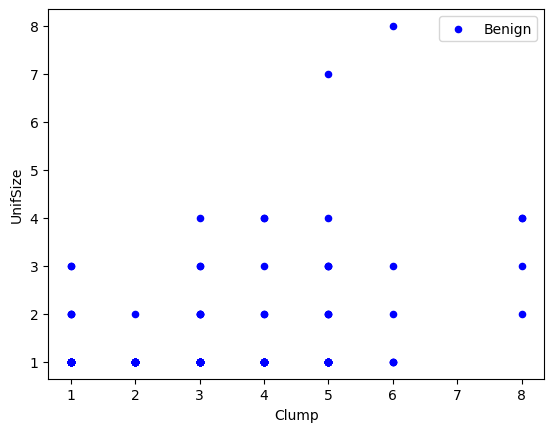

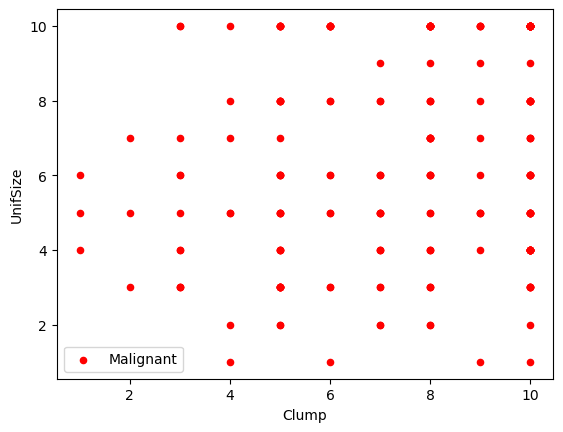

In [17]:
benign_df = cell_df[cell_df['Class'] == 2][0:200]
malignant_df = cell_df[cell_df['Class'] == 4][0:200]
axes = benign_df.plot(kind = 'scatter', x = 'Clump', y = 'UnifSize', color = 'blue', label = 'Benign')
malignant_df.plot(kind = 'scatter', x = 'Clump', y = 'UnifSize', color = 'red', label = 'Malignant')

In [18]:
cell_df = cell_df[pd.to_numeric(cell_df['BareNuc'], errors = 'coerce').notnull()]
cell_df['BareNuc'] = cell_df['BareNuc'].astype('int')

In [19]:
cell_df.dtypes

ID             int64
Clump          int64
UnifSize       int64
UnifShape      int64
MargAdh        int64
SingEpiSize    int64
BareNuc        int32
BlandChrom     int64
NormNucl       int64
Mit            int64
Class          int64
dtype: object

In [21]:
cell_df.columns

Index(['ID', 'Clump', 'UnifSize', 'UnifShape', 'MargAdh', 'SingEpiSize',
       'BareNuc', 'BlandChrom', 'NormNucl', 'Mit', 'Class'],
      dtype='object')

In [22]:
# selecting the input features

feature_df = cell_df[['Clump', 'UnifSize', 'UnifShape', 'MargAdh', 'SingEpiSize',
       'BareNuc', 'BlandChrom', 'NormNucl', 'Mit']]

In [23]:
# convert the features into a numpy array
X = np.array(feature_df)

In [24]:
# selecting the target variable
y = np.asarray(cell_df['Class'])

In [27]:
# display the first five rows
X[0:5]

array([[ 5,  1,  1,  1,  2,  1,  3,  1,  1],
       [ 5,  4,  4,  5,  7, 10,  3,  2,  1],
       [ 3,  1,  1,  1,  2,  2,  3,  1,  1],
       [ 6,  8,  8,  1,  3,  4,  3,  7,  1],
       [ 4,  1,  1,  3,  2,  1,  3,  1,  1]], dtype=int64)

In [28]:
# split the data

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 1)


In [29]:
X_train.shape

(546, 9)

In [30]:
from sklearn import svm

In [31]:
classifier = svm.SVC(kernel='linear', gamma='auto', C=2)
classifier.fit(X_train, y_train)


SVC(C=2, gamma='auto', kernel='linear')

In [32]:
# predict the classes of the test data
y_predict = classifier.predict(X_test)

In [33]:
# import the classification report
from sklearn.metrics import classification_report

# print the classification report
print(classification_report(y_test, y_predict))

              precision    recall  f1-score   support

           2       0.98      1.00      0.99        90
           4       1.00      0.96      0.98        47

    accuracy                           0.99       137
   macro avg       0.99      0.98      0.98       137
weighted avg       0.99      0.99      0.99       137

